In [15]:
import analysis as an
import pandas as pd
from plotnine  import *
import matplotlib.pyplot as plt
import numpy as np 


data_directory = 'data'
series_prefixes = ['POLL', 'UMWAIT', 'SEM']  # Add more prefixes as needed

bench_data = an.load_data(data_directory, series_prefixes, 'bench')
rusage_data = an.load_data(data_directory, series_prefixes, 'rusage')

mean_latency_with_stdev_per_series = bench_data.groupby(['Name']).agg(nsop_mean=('ns/op', 'mean'), nsop_sem=('ns/op', 'sem')).reset_index()

mean_cpu_time_ctx_switches = rusage_data.groupby(['series_name']).agg(user_CPU_timesec_mean=('user_CPU_time(sec)', 'mean'), system_CPU_timesec_mean=('system_CPU_time(sec)', 'mean'), voluntary_context_switches_mean=('voluntary_context_switches', 'mean'), involuntary_context_switches_mean=('involuntary_context_switches', 'mean')).reset_index()




0    238.2
1     28.5
2    235.4
Name: involuntary_context_switches_mean, dtype: float64

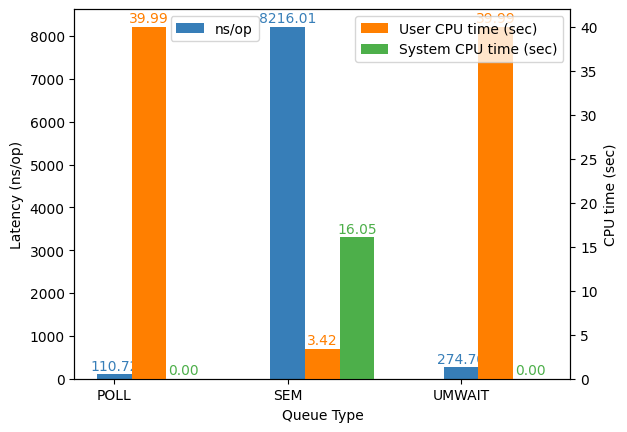

In [45]:

merged_data = pd.merge(mean_latency_with_stdev_per_series, mean_cpu_time_ctx_switches, left_on='Name', right_on='series_name', how='outer')

# ggplot(merged_data, aes(x="Name", y="nsop_mean", fill="Name"))  \
# + geom_col()  \
# + geom_errorbar(aes(ymin="nsop_mean - nsop_sem", ymax="nsop_mean + nsop_sem"), width=0.2) 


fig = plt.figure() # Create matplotlib figure  
ax = fig.add_subplot(111) # Create matplotlib axes
ax2 = ax.twinx()


CB_color_cycle = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']



merged_data['total_CPU_timesec_mean'] = merged_data['user_CPU_timesec_mean'] + merged_data['system_CPU_timesec_mean']


width = 0.2
N = len(merged_data['Name'])
ind = np.arange(N)

bars1 = ax.bar(ind, merged_data['nsop_mean'], width,color='#377eb8')
bars2 = ax2.bar(ind + width, merged_data['user_CPU_timesec_mean'], width, color='#ff7f00')
bars3 = ax2.bar(ind + width*2, merged_data['system_CPU_timesec_mean'], width, color='#4daf4a')

# Add value labels on top of each bar
for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha='center', color='#377eb8')

for bar in bars2:
    height = bar.get_height()
    ax2.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha='center', color='#ff7f00')

for bar in bars3:
    height = bar.get_height()
    ax2.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha='center', color='#4daf4a')

# Set the labels and title
ax.set_xlabel('Queue Type')
ax.set_ylabel('Latency (ns/op)')
ax2.set_ylabel('CPU time (sec)')


# Set the x-ticks to use the values in the dataframe
ax.set_xticks(range(len(merged_data['Name'])))
ax.set_xticklabels(merged_data['Name'])

# Create a legend
ax.legend(['ns/op'], loc='upper left', bbox_to_anchor=(0.18, 1))
ax2.legend(['User CPU time (sec)', 'System CPU time (sec)'], loc='upper right')

plt.show()


